In [40]:
import numpy as np 
from scipy import stats
import matplotlib.pyplot as plt

unif = stats.uniform(-1,2) #this creates a uniform over the range [-1,1]

def f(x):
    return x**2

sample_sum = 0
N = 10000
circle_sum = 0
x_circle_vals = []
y_circle_vals = []
x_no_circle_vals =[]
y_no_circle_vals =[]
for i in range(N):
    s = unif.rvs()
    t = unif.rvs()
    call = f(s)
    call_2 = f(t)
    if call + call_2 < 1:
        circle_sum += 1
        x_circle_vals.append(s)
        y_circle_vals.append(t)
    else:
        x_no_circle_vals.append(s)
        y_no_circle_vals.append(t)
    sample_sum += call


sample_sum /= N
pi = 4*circle_sum/N
print(pi)
print("integral as estimated from 100000 Samples: {}".format(sample_sum))
print("pi evaluated to be: {}".format(pi))

3.1556
integral as estimated from 100000 Samples: 0.3356922656806703
pi evaluated to be: 3.1556


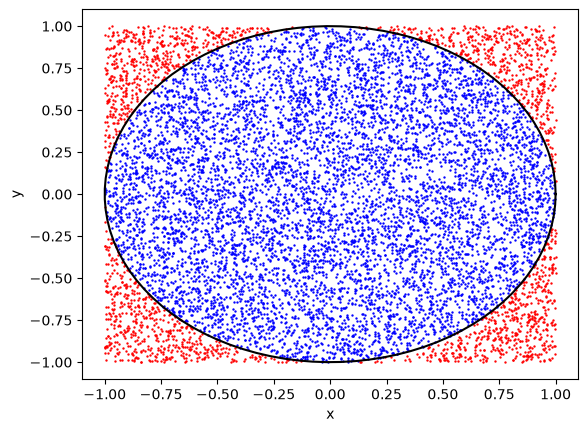

In [ ]:
theta = np.linspace(0, 2*np.pi, 100)

plt.figure()
plt.scatter(x_circle_vals, y_circle_vals, c='b', s=0.5)
plt.scatter(x_no_circle_vals, y_no_circle_vals, c='r', s=0.5)
plt.plot(np.cos(theta), np.sin(theta), 'k')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [28]:
N = 100000
for i in range(N):
    s = unif.rvs()
    call = f(s)
    sample_sum += call
    
sample_sum /= N
print("integral as estimated from 100,000 Samples: {}".format(sample_sum))

integral as estimated from 100,000 Samples: 2.3338279898524514


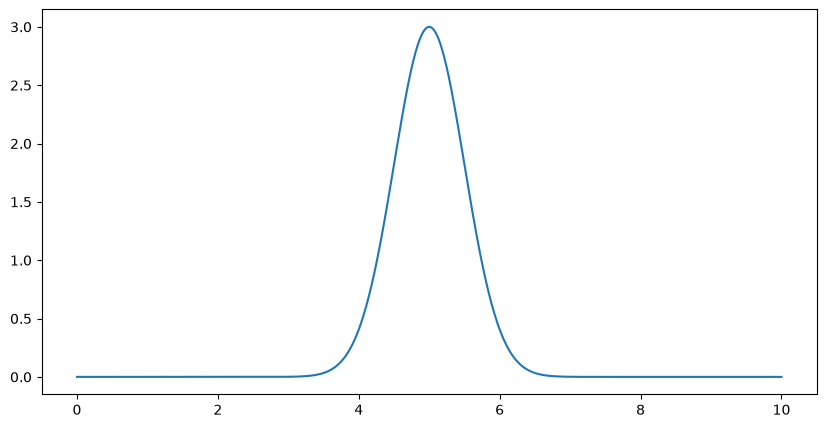

In [29]:
def f2(x):
    out = 3 * np.exp(-(x-5.)**2/(2*0.5**2))
    return out

xx = np.linspace(0,10,1000)
y = f2(xx)
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(xx,y);

In [30]:
#f(x) is not normalized, it's just something with a gaussian form, as I've multiplied by a constant
def f2(x):
    return 3 * np.exp(-(x-5.)**2/(2*0.5**2))

gauss = stats.norm(5,0.5) #this is my new p(theta)
N=100000
area = []
for i in range(N):
    val = gauss.rvs()
    call = f2(val) / gauss.pdf(val)
    area.append(call)
    
norm_area = np.sum(area) / N

print('Calculated Area: {}'.format(norm_area))

Calculated Area: 3.7599424119464997


In [31]:
area_theoretical = np.sqrt(2*np.pi*0.5**2)*3
area_theoretical

np.float64(3.7599424119465006)

In [77]:
def MCMC(function, init_theta, N):
    theta = init_theta
    theta_chain = [init_theta]

    for i in range(N):
        theta_prime = theta + np.random.normal(0, 1)

        r = np.random.uniform(0,1)

        log_diff = np.log(function(theta_prime))-np.log(function(theta))

        if np.log(r) < log_diff:
                theta = theta_prime
        theta_chain.append(theta)

        

    return np.array(theta_chain)

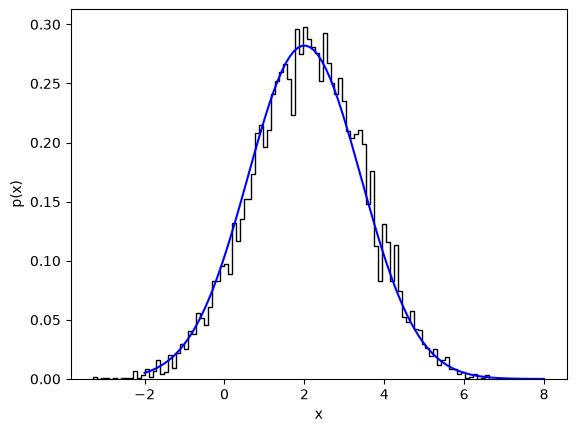

In [89]:
def gaussian(x):
    return (1/(np.sqrt(4*np.pi)))*np.exp((-((x-2)/np.sqrt(2))**2)/2)

n = 10000
x_init = 0
x_vals = np.linspace(-2, 8, 100)

y = gaussian(x_vals)

y_prime = MCMC(gaussian, x_init, n)

plt.hist(y_prime, bins=100, density=True, color='k', histtype='step')
plt.plot(x_vals, y, c = 'b')
plt.xlabel('x')
plt.ylabel('p(x)')
plt.show()